HTTP Status Frequency: {'304': 186, '404': 43, '200': 115}
IP Frequency: {'10.73.146.189': 6, '10.73.145.224': 107, '10.73.133.231': 44, '10.73.132.212': 47, '10.73.144.159': 6, '10.73.133.204': 96, '10.73.132.5': 38}
CSV files created successfully


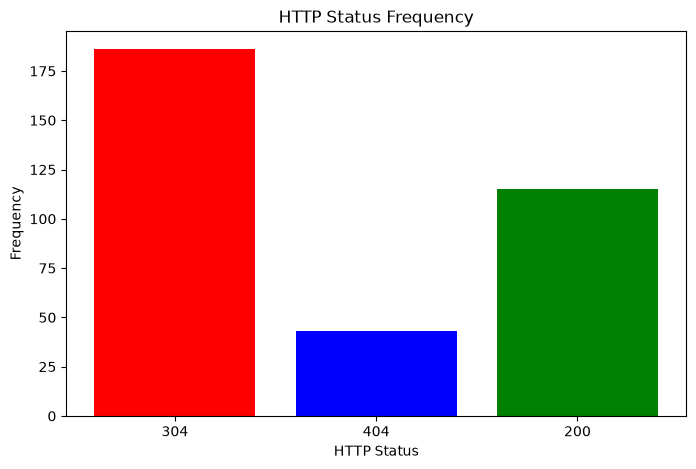

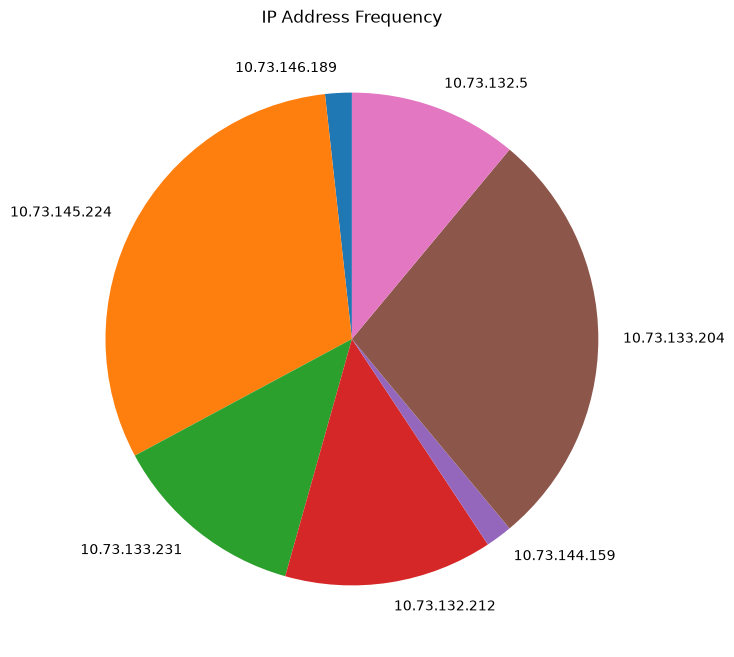

In [5]:
import os
import csv
import shlex
import pandas as pd
import matplotlib.pyplot as plt

path = os.path.join("C:\\Users\\dines\\Documents")
filename = "mylog.log"
ip = []
http_status = []

with open(os.path.join(path, filename), "r") as f:
    for each_line in f:
        mylist = shlex.split(each_line)
        ip_address = mylist[3].split(":")[0]
        status = mylist[8]
        ip.append(ip_address)
        http_status.append(status)
        
def frequency(mylist):
    mydict = {}

    for each in mylist:
        if each not in mydict:
            mydict[each] = 1
        else:
            mydict[each] += 1

    return mydict

def write_to_csv(mydict, filename):
    with open(os.path.join(path, filename), "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["Sno", "Value", "Frequency"])
        sno = 1
        for each, count in mydict.items():
            writer.writerow([sno, each, count])
            sno += 1

x = frequency(http_status)
print("HTTP Status Frequency:", x)
y = frequency(ip)
print("IP Frequency:", y)

write_to_csv(x, "http_status_frequency.csv")
write_to_csv(y, "ip_frequency.csv")
print("CSV files created successfully")
df_status = pd.DataFrame(
    list(x.items()),
    columns=["HTTP_Status", "Frequency"]
)

df_ip = pd.DataFrame(
    list(y.items()),
    columns=["IP_Address", "Frequency"]
)

plt.figure(figsize=(8, 5))

colors = ["red", "blue", "green", "orange", "purple", "gold"]

plt.bar(
    df_status["HTTP_Status"],
    df_status["Frequency"],
    color=colors[:len(df_status)]
)

plt.xlabel("HTTP Status")
plt.ylabel("Frequency")
plt.title("HTTP Status Frequency")
plt.show()

plt.figure(figsize=(8, 8))

plt.pie(
    df_ip["Frequency"],
    labels=df_ip["IP_Address"],
    startangle=90
)

plt.title("IP Address Frequency")

plt.show()